# Forças resultantes no foguete

In [3]:
# !pip install import_ipynb

In [236]:
%%capture

import numpy as np
import matplotlib.pyplot as plt

import import_ipynb
from atmosfera import gravidade_efetiva, temperatura, rho, Rg, Mm

In [237]:
import pandas as pd

data_estagios = pd.DataFrame([
    {
        "A": 289.6015,
        "V": 12_181.3369,
        "ms": 133_583,
        "mc": 2_148_213,
        "Ab": 49.677
    },
    {
        "A": 79.4598,
        "V": 1973.8777,
        "ms": 38_442,
        "mc": 437_595,
        "Ab": 15.021
    },
    {
        "A": 34.3589,
        "V": 621.0478,
        "ms": 15_173+1_918,
        "mc": 101_822,
        "Ab": 3.004
    },
])


foguete = {
    "estagio": 0,
    "phi": np.pi / 2,
    "theta": 0,
    "v": np.array([0, 0, 0]),
    "V": data_estagios["V"].sum(),
    "A": data_estagios["A"].iloc[0],
    "mt": data_estagios["ms"].sum() + data_estagios["mc"].sum(),
    "cg": 0,
    "c": 1,
    "vm": 100,
    "p": np.array([0., 0., 0.])
}

foguete

{'estagio': 0,
 'phi': 1.5707963267948966,
 'theta': 0,
 'v': array([0, 0, 0]),
 'V': np.float64(14776.2624),
 'A': np.float64(289.6015),
 'mt': np.int64(2876746),
 'cg': 0,
 'c': 1,
 'vm': 100,
 'p': array([0., 0., 0.])}

## Empuxo de arquimedes:

$E_a=\rho(h)g(h)v$

- $\rho$: Densidade da camada atual

- $g$: gravidade na camada atual

- $v$: volume do foguete

In [238]:
X = np.array([1, 0, 0])
Y = np.array([0, 1, 0])
Z = np.array([0, 0, 1])

def Ea(foguete):
    return Z * (rho(foguete["p"][2]) * gravidade_efetiva(foguete["p"][2]) * foguete["V"])

print(*Ea(foguete), sep=" | ")

0.0 | 0.0 | 177509.40123957643


## Velocidade do som

$$V_s = \sqrt{\frac{\gamma R_G T(h)}{Mm}}$$

In [239]:
gamma = 1.4

def Vs(h):
    return np.sqrt((gamma*Rg*temperatura(h))/Mm)

Vs(11_000)

np.float64(295.07212805398495)

In [240]:
lista_mach = [0, 0.5, 1.0, 1.25, 1.5, 2.0, 2.5,
              3.0, 4.0, 5.0, 7.0, 9.0, 10.0]

lista_cd = [0.300, 0.260, 0.375, 0.510, 0.550,
            0.470, 0.350, 0.270, 0.210, 0.200,
            0.230, 0.260, 0.260]


def coeficiente_arrasto(M, mach=lista_mach, cd=lista_cd):
    return np.interp(M, mach, cd)


# Exemplo
M = 1.1
CD = coeficiente_arrasto(M)

print(f"Mach = {M}")
print(f"CD = {CD:.3f}")

Mach = 1.1
CD = 0.429


## Arrasto da nave:

$F_D=-\frac{1}{2}C_D\rho(h)A|v|\vec{v}$

- $C_D$: Coeficiente de arrasto

- $\rho$: Densidade da camada atual

- $A$: Área efetiva do foguete

- $v$: Velocidade do foguete


In [246]:
def Fd(foguete):
    norm_v = np.linalg.vector_norm(foguete["v"])
    Cd = coeficiente_arrasto(norm_v / Vs(foguete["p"][2]))  
    
    return -(1/2) * Cd * rho(foguete["p"][2]) * foguete["A"] * np.linalg.vector_norm(foguete["v"]) * foguete["v"]

print(*Fd(foguete), sep=" | ")

-0.0 | -0.0 | -0.0


## Empuxo do motor:

$T= c( \dot{m} \mu_e + (P_e-P_a)A_e)$
- $c$: Coeficiente de correção do bocal
- $\dot{m}$: Vazão de massa do bocal
- $\mu_e$: Velocidade relativa dos gases na saída
- $P_e$: Pressão de exaustão
- $P_a$: Pressão atmosférica de saída
- $A_e$: Área do bucal
 

In [247]:

Ki = 1385
cp = (Rg * gamma) / (gamma - 1) 
Tad = 3500
Tw = 800
    
Resp = Rg / Mm

vmx = Ki / cp

def t_camara_combustao(foguete):
    return Tw + (Tad - Tw) * (foguete["vm"] / (foguete["vm"] + vmx))

def p_camara_combustao(foguete):
    return (foguete["vm"] / data_estagios["Ab"].iloc[foguete["estagio"]]) * np.sqrt((Resp * t_camara_combustao(foguete)) / gamma) * ((gamma + 1) / 2) ** ((gamma + 1) / (2 * (gamma - 1)))

def angulo_ataque(phi, theta):
    sen_phi, sen_theta, cos_phi, cos_theta = np.sin(phi), np.sin(theta), np.cos(phi), np.cos(theta), 
    
    return (
        (cos_phi * sen_theta * X) +
        (cos_phi * cos_theta * Y) +
        (sen_phi * Z)
    )
def Em(foguete):
    if foguete["vm"] == 0:
        return 0
    
    pa = (rho(foguete["p"][2]) * Rg * temperatura(foguete["p"][2])) / Mm
    Tc = t_camara_combustao(foguete)
    Pc = p_camara_combustao(foguete) + pa
    
    # print(f"{Pc = :.2f} | {pa = :.2f}")
    
    mue = np.sqrt(((2 * gamma * Resp * Tc)/(gamma - 1)) * (1 - (pa / Pc) ** ((gamma -1)/gamma)))
    
    modulo = foguete["c"] * (foguete["vm"] * mue + (Pc - pa) * data_estagios["Ab"].iloc[foguete["estagio"]])

    return modulo * angulo_ataque(foguete["phi"], foguete["theta"])

Em(foguete)


array([0.00000000e+00, 8.95397145e-12, 1.46229451e+05])

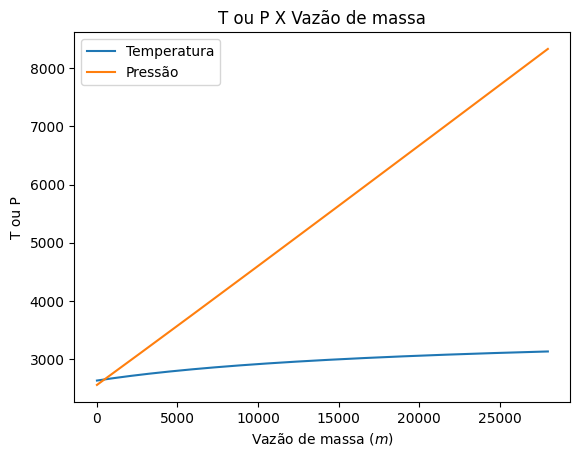

In [248]:
f1 = foguete.copy()

x = np.linspace(0, 28_000, 200)
t = []
p = []

for i in x:
    t.append(t_camara_combustao(f1))
    p.append(p_camara_combustao(f1))
    
    f1["vm"] += 1

plt.plot(x, t, label="Temperatura")
plt.plot(x, p, label="Pressão")
plt.xlabel("Vazão de massa ($m$)")
plt.ylabel("T ou P")
plt.title("T ou P X Vazão de massa")
plt.legend()
plt.show()

In [249]:
def resultante_foguete(foguete):
    print(f"""
{foguete["mt"] = :.2f}
{gravidade_efetiva(foguete["p"][2]) = :.2f}
{Ea(foguete) = }
{Fd(foguete) = }
{Em(foguete) = }
{foguete["v"] = }
""")
    
    return foguete["mt"] * gravidade_efetiva(foguete["p"][2]) * (-Z) + Ea(foguete) + Fd(foguete) + Em(foguete)

resultante_foguete(foguete)


foguete["mt"] = 2876746.00
gravidade_efetiva(foguete["p"][2]) = 9.81
Ea(foguete) = array([     0.        ,      0.        , 177509.40123958])
Fd(foguete) = array([-0., -0., -0.])
Em(foguete) = array([0.00000000e+00, 8.95397145e-12, 1.46229451e+05])
foguete["v"] = array([0, 0, 0])



array([ 0.00000000e+00,  8.95397145e-12, -2.78875023e+07])